# Motor Control Models
In this notebook, we explore mathematical models of motor control, focusing on the minimum jerk model for describing human reaching movements.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

## 1. Minimum Jerk Trajectory
Human reaching movements are often characterized by smooth trajectories that minimize the rate of change of acceleration, known as 'jerk'.

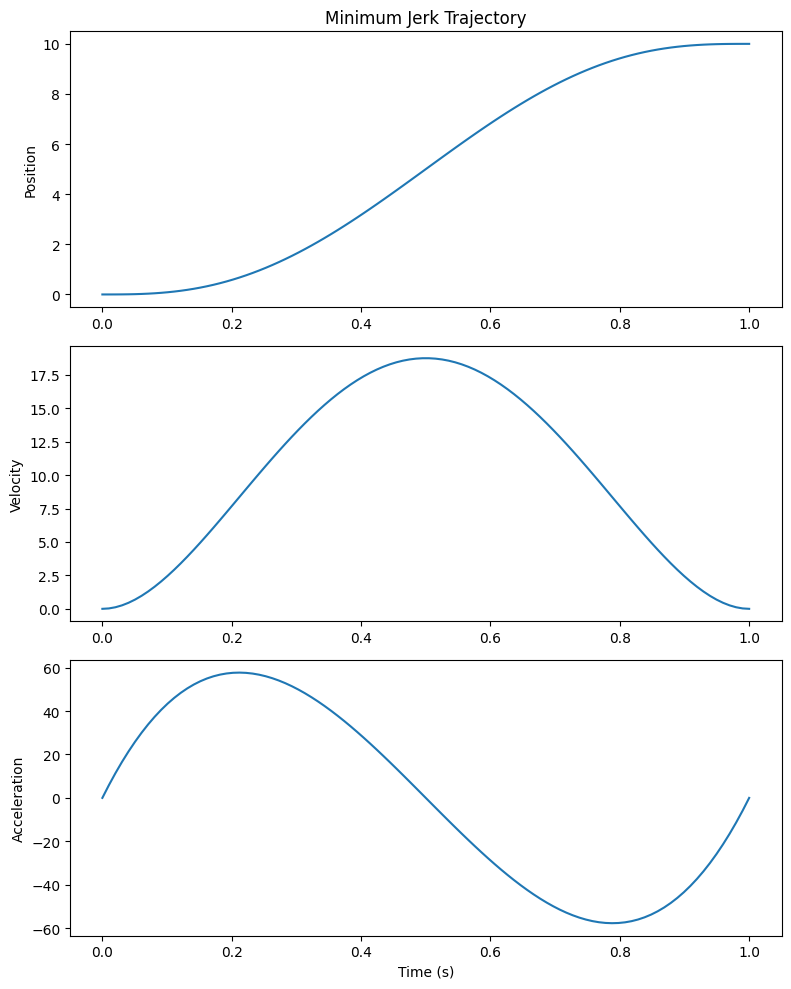

In [2]:
def min_jerk_trajectory(x0, xf, t0, tf, t):
    """Calculates the minimum jerk trajectory (position, velocity, acceleration)."""
    tau = (t - t0) / (tf - t0)
    
    # 5th order polynomial for minimum jerk
    pos = x0 + (xf - x0) * (10 * tau**3 - 15 * tau**4 + 6 * tau**5)
    
    # Velocity (derivative of position with respect to t)
    vel = (xf - x0) / (tf - t0) * (30 * tau**2 - 60 * tau**3 + 30 * tau**4)
    
    # Acceleration (derivative of velocity with respect to t)
    acc = (xf - x0) / (tf - t0)**2 * (60 * tau - 180 * tau**2 + 120 * tau**3)
    
    return pos, vel, acc

# Time vector
t = np.linspace(0, 1, 100)
x0 = 0  # Initial position
xf = 10 # Final position

pos, vel, acc = min_jerk_trajectory(x0, xf, 0, 1, t)

# Plotting
fig, axs = plt.subplots(3, 1, figsize=(8, 10))

axs[0].plot(t, pos)
axs[0].set_ylabel('Position')
axs[0].set_title('Minimum Jerk Trajectory')

axs[1].plot(t, vel)
axs[1].set_ylabel('Velocity')

axs[2].plot(t, acc)
axs[2].set_xlabel('Time (s)')
axs[2].set_ylabel('Acceleration')

plt.tight_layout()
plt.show()